# What do finite differences cost ?

In the previous notebook we found the slope without doing any calculus: nudge a parameter,
see how the loss moves, divide. It works, and it needs nothing but the model itself.

That notebook ended on a claim: *"it is quite costly in compute"*. This one makes the bill
explicit, because the price is not the point. **How the price grows is the point.**

Our model so far has two parameters, $\color{#FFB454}{a}$ and $\color{#FFB454}{b}$.
Real models have millions. So the only question that matters here is:

> when the number of parameters grows, what happens to the cost of one step ?

# Setup

In [ ]:
# ABOUTME: Measures what one finite-difference gradient costs as the parameter count grows.
# ABOUTME: Counts cost evaluations first, then confirms the count with the clock.
%matplotlib widget

import time

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, widgets

In [ ]:
# The same auction house, with more to measure. One sculpture used to be a single number
# (its weight); now it is a row of measurements: weight, height, age, width, ...
# Every measurement comes with one parameter to learn, plus the base price, so:
#       n_params = n_measurements + 1
rng = np.random.default_rng(0)
N_SCULPTURES = 500


def make_auction_data(n_params):
    # Measurements are centred (a difference from the average sculpture) so that the fit stays
    # equally easy at every size. Without that, "more parameters" would also quietly mean
    # "harder problem", and we could not tell the two apart.
    X = rng.random((N_SCULPTURES, n_params - 1)) - 0.5
    true_theta = rng.random(n_params) * 3
    y = true_theta[0] + X @ true_theta[1:] + rng.normal(0, 0.3, N_SCULPTURES)
    return X, y


def predict(X, theta):
    """Base price, plus one parameter times one measurement, for every measurement."""
    return theta[0] + X @ theta[1:]


def get_cost(y, y_hat):
    return ((y - y_hat) ** 2).sum()


X, y = make_auction_data(2)
print(f"{N_SCULPTURES} sculptures, {X.shape[1]} measurement each, so 2 parameters to learn")

500 sculptures, 1 measurement each, so 2 parameters to learn


# 1. Count the evaluations on the case you already know

Take the picture from the previous notebook: two parameters, one step of finite differences.

Before running anything, count it yourself. To work out both slopes, how many times do we have
to compute the $\color{#56D4F5}{\text{loss}}$ ?

Let's make the computer count, so there is no arguing.

In [ ]:
class CountingCost:
    """The cost function, with a turnstile on the door."""

    def __init__(self, X, y):
        self.X, self.y, self.calls = X, y, 0

    def __call__(self, theta):
        self.calls += 1
        return get_cost(self.y, predict(self.X, theta))


def finite_difference_gradient(cost, theta, h=1e-5):
    """One slope per parameter, each one bought with its own nudge."""
    base = cost(theta)                      # where we stand now
    gradient = np.empty_like(theta)
    for j in range(len(theta)):
        bumped = theta.copy()
        bumped[j] += h                      # nudge parameter j, and only parameter j
        gradient[j] = (cost(bumped) - base) / h
    return gradient


for n_params in (2, 5, 10, 50):
    X, y = make_auction_data(n_params)
    cost = CountingCost(X, y)
    finite_difference_gradient(cost, np.zeros(n_params))
    print(f"{n_params:>3} parameters  ->  {cost.calls:>3} cost evaluations for ONE step")

  2 parameters  ->    3 cost evaluations for ONE step
  5 parameters  ->    6 cost evaluations for ONE step
 10 parameters  ->   11 cost evaluations for ONE step
 50 parameters  ->   51 cost evaluations for ONE step


There is no mystery in those numbers:

$$
\text{evaluations for one step} = \underbrace{1}_{\text{where we stand}}
+ \underbrace{\color{#FFB454}{P}}_{\text{one nudge per parameter}}
$$

Each parameter has to be nudged **on its own**, because nudging two at once tells you how the
loss moved, but not which of the two moved it. So the bill is one evaluation per parameter, and
there is no way to share them.

Two parameters hides this completely: 3 instead of 1 is nothing. Move the slider.

In [ ]:
@interact(n_params=widgets.IntSlider(value=2, min=2, max=1000, step=1, description="parameters:"))
def the_bill(n_params):
    per_step = n_params + 1
    # 1000 steps is a short training run, and 1 ms is a fast model. Both are generous.
    print(f"{n_params:>6,} parameters")
    print(f"     one step      = {per_step:>12,} cost evaluations")
    print(f"     1000 steps    = {per_step * 1000:>12,} cost evaluations")
    print(f"     at 1 ms each  = {per_step * 1000 / 1000:>12,.0f} seconds"
          f"  ({per_step * 1000 / 1000 / 3600:,.1f} hours)")

interactive(children=(IntSlider(value=2, description='parameters:', max=1000, min=2), Output()), _dom_classes=…

# 2. Does the clock agree ?

Counting is an argument. Let's check it against a stopwatch, and time two things:

- one **finite-difference step**
- one **single cost evaluation**

If the counting is right, the first should cost about $\color{#FFB454}{P}+1$ of the second,
whatever the machine. Dividing one by the other is what makes the hardware cancel out.

In [ ]:
def best_of(fn, k=5):
    """Fastest of k runs: the slow ones are the operating system, not the code."""
    fn()                                    # warm up, so the first run does not pay for caches
    timings = []
    for _ in range(k):
        t0 = time.perf_counter()
        fn()
        timings.append(time.perf_counter() - t0)
    return min(timings)


PARAM_COUNTS = (2, 5, 10, 25, 50, 100, 250, 500)
step_ms, eval_ms, eval_us, in_evaluations = [], [], [], []

print(f"{'parameters':>11} {'one step':>12} {'one evaluation':>16} {'step, in evaluations':>22}")
for n_params in PARAM_COUNTS:
    X, y = make_auction_data(n_params)
    cost = CountingCost(X, y)
    theta = np.zeros(n_params)
    t_step = best_of(lambda: finite_difference_gradient(cost, theta))
    t_eval = best_of(lambda: cost(theta), k=20)
    step_ms.append(t_step * 1e3)
    eval_ms.append(t_eval * 1e3)
    eval_us.append(t_eval * 1e6)
    in_evaluations.append(t_step / t_eval)
    print(f"{n_params:>11} {t_step*1e3:>9.3f} ms {t_eval*1e6:>13.2f} us {t_step/t_eval:>19.1f}")

 parameters     one step   one evaluation   step, in evaluations
          2     0.023 ms          6.84 us                 3.4
          5     0.046 ms          6.95 us                 6.7
         10     0.086 ms          7.05 us                12.2
         25     0.213 ms          7.39 us                28.8
         50     0.509 ms          9.18 us                55.5
        100     1.268 ms         11.70 us               108.4
        250     4.915 ms         18.42 us               266.8
        500    16.169 ms         30.68 us               527.1


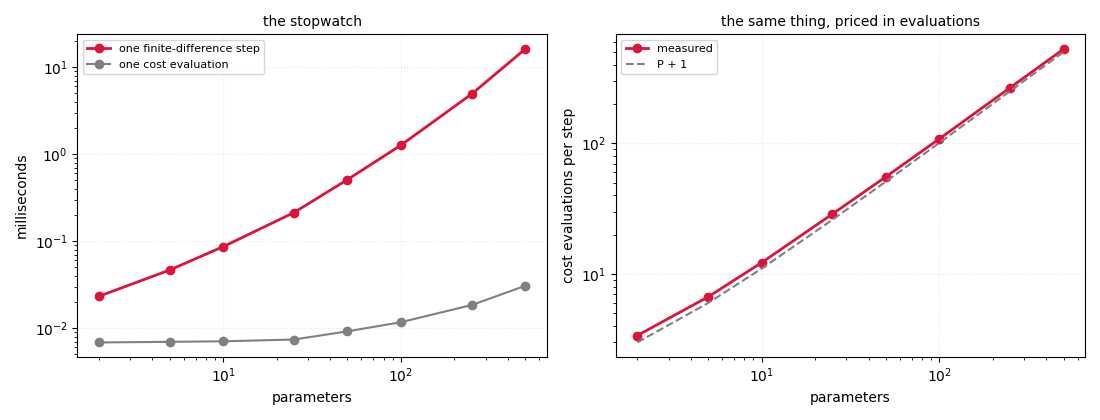

In [ ]:
fig_clock, (ax_ms, ax_ev) = plt.subplots(1, 2, figsize=(11, 4.2))

ax_ms.plot(PARAM_COUNTS, step_ms, "o-", c="crimson", lw=2, label="one finite-difference step")
ax_ms.plot(PARAM_COUNTS, eval_ms, "o-", c="gray", lw=1.5, label="one cost evaluation")
ax_ms.set_xscale("log"); ax_ms.set_yscale("log")
ax_ms.set_xlabel("parameters"); ax_ms.set_ylabel("milliseconds")
ax_ms.set_title("the stopwatch", fontsize=10); ax_ms.legend(fontsize=8)
ax_ms.grid(alpha=0.3, ls=":")

ax_ev.plot(PARAM_COUNTS, in_evaluations, "o-", c="crimson", lw=2, label="measured")
ax_ev.plot(PARAM_COUNTS, [p + 1 for p in PARAM_COUNTS], "--", c="gray", lw=1.5, label="P + 1")
ax_ev.set_xscale("log"); ax_ev.set_yscale("log")
ax_ev.set_xlabel("parameters"); ax_ev.set_ylabel("cost evaluations per step")
ax_ev.set_title("the same thing, priced in evaluations", fontsize=10); ax_ev.legend(fontsize=8)
ax_ev.grid(alpha=0.3, ls=":")

fig_clock.tight_layout()

The right panel is the one to keep. The measured line sits on
$\color{#FFB454}{P}+1$ across more than two decades, and it would sit there on your laptop
too: we divided a time by a time, so the machine cancelled out.

The left panel is steeper than the right, and that is worth a second of attention. The grey line
is not flat: with more measurements per sculpture, a single evaluation is itself more work. So the
wall clock pays **twice**, once for more evaluations and once for bigger ones.

Only the first of those two is a law of finite differences. The second depends on the model.
When you carry one number out of this notebook, carry $\color{#FFB454}{P}+1$.

# 3. What it costs to actually fit something

One step is not a fit. Let's run the whole thing: start from zero, step until the loss is within
1% of the best this model can possibly do, and count the turnstile.

In [ ]:
CONVERGENCE_COUNTS = (2, 5, 10, 25, 50, 100)
steps_taken, evaluations_taken, seconds_taken = [], [], []

print(f"{'parameters':>11} {'steps':>7} {'evaluations':>13} {'seconds':>9}")
for n_params in CONVERGENCE_COUNTS:
    X, y = make_auction_data(n_params)
    # The best cost reachable at all, so "converged" means the same thing at every size.
    design = np.hstack([np.ones((N_SCULPTURES, 1)), X])
    best_theta, *_ = np.linalg.lstsq(design, y, rcond=None)
    floor = get_cost(y, design @ best_theta)

    cost = CountingCost(X, y)
    theta, learning_rate, steps = np.zeros(n_params), 4e-4, 0
    t0 = time.perf_counter()
    while cost(theta) > floor * 1.01 and steps < 5000:
        theta = theta - learning_rate * finite_difference_gradient(cost, theta)
        steps += 1
    elapsed = time.perf_counter() - t0

    steps_taken.append(steps); evaluations_taken.append(cost.calls); seconds_taken.append(elapsed)
    print(f"{n_params:>11} {steps:>7} {cost.calls:>13,} {elapsed:>9.3f}")

 parameters   steps   evaluations   seconds
          2      85           341     0.003
          5     101           708     0.006
         10     126         1,513     0.013
         25     156         4,213     0.042


         50     199        10,349     0.136


        100     276        28,153     0.396


2 -> 100 parameters is 50x the parameters, and 83x the evaluations


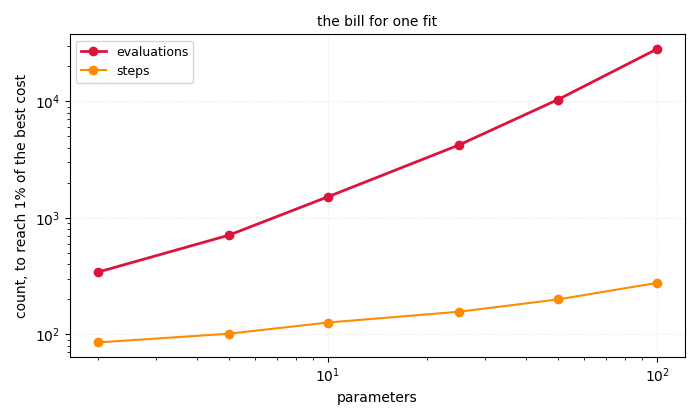

In [ ]:
fig_fit, ax_fit = plt.subplots(figsize=(7, 4.2))
ax_fit.plot(CONVERGENCE_COUNTS, evaluations_taken, "o-", c="crimson", lw=2, label="evaluations")
ax_fit.plot(CONVERGENCE_COUNTS, steps_taken, "o-", c="darkorange", lw=1.5, label="steps")
ax_fit.set_xscale("log"); ax_fit.set_yscale("log")
ax_fit.set_xlabel("parameters"); ax_fit.set_ylabel("count, to reach 1% of the best cost")
ax_fit.set_title("the bill for one fit", fontsize=10)
ax_fit.legend(fontsize=9); ax_fit.grid(alpha=0.3, ls=":")
fig_fit.tight_layout()

first, last = evaluations_taken[0], evaluations_taken[-1]
print(f"{CONVERGENCE_COUNTS[0]} -> {CONVERGENCE_COUNTS[-1]} parameters is "
      f"{CONVERGENCE_COUNTS[-1] // CONVERGENCE_COUNTS[0]}x the parameters, "
      f"and {last / first:.0f}x the evaluations")

Two things grew at once there, and they are not the same kind of thing:

| what grew | by how much | is it a law ? |
|---|---|---|
| evaluations **per step** | exactly $\color{#FFB454}{P}+1$ | **yes**, always, for any model |
| **steps** to converge | a few times over | no, that depends on the data |

The second one is about this particular fit getting harder, and a better optimiser would shrink
it. The first one no optimiser can touch: it is what the method *is*. And the two multiply.

# 4. Now put a real model in it

Our model has 2 parameters. Let's keep the method and change only
$\color{#FFB454}{P}$, assuming a model fast enough to run in **one millisecond**.

In [ ]:
MILLISECOND = 1e-3
YEAR = 365 * 24 * 3600


def readable(seconds):
    for unit, size in (("years", YEAR), ("days", 86400), ("hours", 3600), ("seconds", 1)):
        if seconds >= size:
            return f"{seconds / size:,.1f} {unit}"
    return f"{seconds * 1000:,.1f} milliseconds"


print(f"{'model':>24} {'parameters':>16} {'ONE step takes':>22}")
for label, n_params in (("our auction house", 2),
                        ("a small network", 10 ** 6),
                        ("GPT-3", 175 * 10 ** 9)):
    print(f"{label:>24} {n_params:>16,} {readable((n_params + 1) * MILLISECOND):>22}")

print(f"\nand a training run is not one step: 100 000 of them on GPT-3 would take "
      f"{readable(100_000 * 175e9 * MILLISECOND)}")

                   model       parameters         ONE step takes
       our auction house                2       3.0 milliseconds
         a small network        1,000,000        1,000.0 seconds
                   GPT-3  175,000,000,000              5.5 years

and a training run is not one step: 100 000 of them on GPT-3 would take 554,921.4 years


# So where does that leave us ?

Finite differences are a fine idea. They need no calculus, they work on any model, and they are
still the standard way to **check** a gradient you wrote by hand.

What kills them is one line: **one nudge buys one derivative.** With
$\color{#FFB454}{P}$ parameters you need $\color{#FFB454}{P}$ nudges, and the moment
$\color{#FFB454}{P}$ is large that is the end of it. No faster computer rescues a method whose
cost is tied to the parameter count, because the parameter count is exactly what we keep growing.

So the question for the next notebook is not "how do we make nudging faster". It is:

> can we get **all** $\color{#FFB454}{P}$ derivatives out of **one** pass ?

The answer is yes, and it is the derivative you learned at school.

<details>
<summary><b>Side note: it is also only an approximation</b></summary>

Cost is what ends finite differences, but precision is the other complaint from the previous
notebook. The nudge `h` is caught between two errors pulling opposite ways:

- **too large** and the slope of the chord is not the slope of the curve (that is the demonstration
  in the next notebook, as $h \to 0$)
- **too small** and `cost(theta + h)` and `cost(theta)` are so close that subtracting them throws
  away most of the digits a float has. Nudge by $10^{-18}$ and you get exactly zero.

So there is a best `h`, in the middle, and the cell below finds it.
</details>

best nudge on this grid: h = 3.49e-10  ->  1.8e-08 relative error on a slope of 53.2


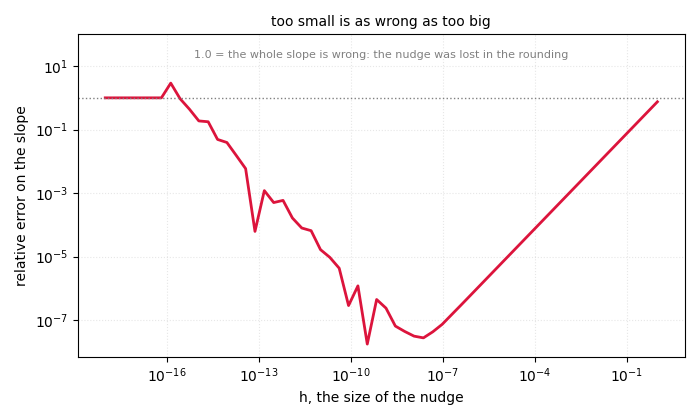

In [ ]:
X, y = make_auction_data(2)
cost = CountingCost(X, y)
theta = np.array([1.0, 1.0])

# The slope we are trying to approximate, worked out by hand for this one parameter:
# d/dtheta_1 of sum((theta_0 + theta_1 * x - y)^2) is sum(2 * error * x).
error = predict(X, theta) - y
exact = (2 * error * X[:, 0]).sum()

hs = np.logspace(-18, 0, 60)
errors = [abs((cost(theta + np.array([0.0, h])) - cost(theta)) / h - exact) / abs(exact)
          for h in hs]

fig_h, ax_h = plt.subplots(figsize=(7, 4.2))
ax_h.plot(hs, errors, c="crimson", lw=2)
ax_h.set_xscale("log"); ax_h.set_yscale("log")
ax_h.axhline(1.0, c="gray", lw=1, ls=":")
ax_h.set_ylim(top=100)   # headroom, so the note below sits clear of the curve
ax_h.text(0.5, 0.95, "1.0 = the whole slope is wrong: the nudge was lost in the rounding",
          transform=ax_h.transAxes, ha="center", va="top", fontsize=8, color="gray")
ax_h.set_xlabel("h, the size of the nudge")
ax_h.set_ylabel("relative error on the slope")
ax_h.set_title("too small is as wrong as too big", fontsize=10)
ax_h.grid(alpha=0.3, ls=":")
fig_h.tight_layout()

best = hs[int(np.argmin(errors))]
print(f"best nudge on this grid: h = {best:.2e}  ->  {min(errors):.1e} relative error "
      f"on a slope of {exact:.1f}")